# CarFair-TN : modélisation du prix

**Objectif** : prédire le prix d'une voiture d'occasion en Tunisie à partir de ses caractéristiques, pour proposer un
« juste prix » dans une application. Les données sont les annonces de **[tayara.tn](https://www.tayara.tn)** explorées dans
`01_eda.ipynb` et nettoyées dans `02_preprocessing.ipynb` (`data/processed/tayara_cars_cleaned.csv`).

**Principes de la démarche**

- **Un jeu de test mis de côté dès le départ** et utilisé une seule fois, à la fin. Tous les choix (encodage, modèle,
  hyperparamètres, variables) sont faits en validation croisée sur l'entraînement uniquement.
- **Une baseline** simple pour savoir ce que vaut réellement un modèle.
- **Une préparation adaptée à chaque famille de modèles**, dans des `Pipeline` scikit-learn : les modèles linéaires ont
  besoin de standardisation et de one-hot, les arbres non. Toute statistique apprise (imputation, encodage) l'est sur
  l'entraînement uniquement, y compris à l'intérieur de chaque fold de validation croisée.
- **Des métriques en dinars** en plus des métriques techniques.
- **Un seul fichier de modèle** contenant tout le pipeline, prêt pour l'application.

### Plan

1. Données et découpage
2. Cible et métriques
3. Baseline
4. Préparation des données par famille de modèles
5. Modèles linéaires : encodage de la variable modèle
6. Comparaison des familles de modèles
7. Optimisation et choix du modèle
8. Sélection de variables
9. Évaluation finale sur le jeu de test
10. Sauvegarde du modèle
11. Bilan

In [1]:
import sys
import json
import warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import xgboost
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV, RepeatedKFold, cross_validate,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.svm import SVR
from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
MODELS_DIR = PROJECT_ROOT / "models"

from src.evaluation import SCORERS, cv_summary, report, to_tnd
from src.features import CategoricalFiller, CategoryDtypeCaster, HierarchicalImputer
from src.models import GroupMedianRegressor

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

C1, C2, C_MUTED = "#2a78d6", "#eb6834", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.axisbelow": True,
})

## 1. Données et découpage

Le modèle utilise 11 variables : 4 numériques (kilométrage, année, cylindrée, puissance fiscale) et 7 catégorielles
(marque, modèle, boîte, carburant, carrosserie, couleur, état). Les valeurs manquantes ont été laissées volontairement
par le preprocessing : les imputations qui s'appuient sur d'autres annonces sont apprises ici, dans les pipelines, sur
l'entraînement uniquement.

**20 % des annonces sont mises de côté comme jeu de test.** Le découpage est **stratifié par décile de prix** : le test
contient la même proportion de citadines, de berlines et de voitures haut de gamme que l'entraînement. Les identifiants des
annonces du test sont enregistrés (`data/processed/test_ids.csv`) pour que le découpage soit reproductible et réutilisable.

Les choix de modélisation sont faits en **validation croisée à 5 folds** sur l'entraînement : chaque modèle est entraîné
5 fois sur 4/5 des données et évalué sur le cinquième restant. On obtient une moyenne et un écart-type, qui indique si
une différence entre deux modèles dépasse le simple bruit.

In [2]:
df = pd.read_csv(PROCESSED_DIR / "tayara_cars_cleaned.csv")

NUM = ["kilometrage", "annee", "cylindree", "puissance_fiscale"]
CAT = ["marque", "modele", "boite", "carburant", "type_de_carrosserie", "couleur_du_vehicule", "etat_du_vehicule"]
FEATURES = NUM + CAT
TARGET = "prix_log"

print(f"{len(df):,} annonces, {len(FEATURES)} variables")
df[FEATURES].isna().sum().rename("valeurs manquantes").to_frame().T

4,257 annonces, 11 variables


,kilometrage,annee,cylindree,puissance_fiscale,marque,modele,boite,carburant,type_de_carrosserie,couleur_du_vehicule,etat_du_vehicule
valeurs manquantes,236,0,373,496,0,156,69,59,441,65,232


In [3]:
price_decile = pd.qcut(df[TARGET], 10, labels=False)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE, stratify=price_decile)

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

test_df[["id_annonce"]].to_csv(PROCESSED_DIR / "test_ids.csv", index=False)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Entraînement : {len(train_df):,} annonces  |  test : {len(test_df):,} annonces (mis de côté)")
pd.DataFrame({
    "prix médian (TND)": [train_df["prix"].median(), test_df["prix"].median()],
    "prix moyen (TND)": [train_df["prix"].mean(), test_df["prix"].mean()],
}, index=["entraînement", "test"]).style.format("{:,.0f}")

Entraînement : 3,405 annonces  |  test : 852 annonces (mis de côté)


,prix médian (TND),prix moyen (TND)
entraînement,"40,999","51,907"
test,"40,900","50,983"


## 2. Cible et métriques

**La cible est `prix_log = log(1 + prix)`.** Trois raisons :

- **Les erreurs qui comptent sont relatives** : se tromper de 10 000 TND est grave pour une citadine à 20 000 TND,
  négligeable pour un 4x4 à 300 000 TND. Sur l'échelle log, une erreur de 10 % pèse pareil quel que soit le prix.
- **La distribution des prix est très asymétrique** : le log évite que quelques voitures de luxe dominent l'apprentissage.
- **Les effets sont multiplicatifs** : une année d'âge fait perdre un pourcentage de la valeur, pas un montant fixe.
  Le log rend ces effets additifs, ce que les modèles linéaires savent représenter.

**Les prédictions sont ramenées en dinars** avec `expm1`, l'inverse de `log1p`. Le résultat estime le **prix médian**
des voitures de ce profil (la moitié se vend plus cher, l'autre moins cher), ce qui correspond bien à l'idée de
« juste prix ».

**Métriques** (définies dans `src/evaluation.py`) :

| Métrique | Échelle | Rôle |
|---|---|---|
| RMSE log | log | métrique optimisée par les modèles, critère de choix |
| MAE (TND) | dinars | erreur moyenne en dinars, lisible par un utilisateur |
| Erreur relative médiane | % | « la moitié des estimations sont à moins de X % du prix réel » |
| Part à ±10 % / ±20 % | % | part des estimations suffisamment proches du prix réel (évaluation finale) |

In [4]:
cv_results = {}

def evaluate_cv(name, model):
    # Validation croisée 5 folds sur l'entraînement : moyenne ± écart-type
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORERS, n_jobs=-1)
    cv_results[name] = cv_summary(res)
    return cv_results[name]

def cv_table(names=None):
    table = pd.DataFrame(cv_results).T
    table = table.loc[names] if names else table
    out = pd.DataFrame({
        "RMSE log": table["rmse_log (moy.)"].map("{:.4f}".format) + " ± " + table["rmse_log (écart-type)"].map("{:.4f}".format),
        "MAE (TND)": table["mae_tnd (moy.)"].map("{:,.0f}".format) + " ± " + table["mae_tnd (écart-type)"].map("{:,.0f}".format),
        "Erreur relative médiane": table["median_ape (moy.)"].map("{:.1f} %".format),
    })
    return out

## 3. Baseline

Avant tout modèle d'apprentissage, une règle simple : **prédire le prix médian des voitures similaires** de
l'entraînement (même marque, même modèle, même année ; à défaut, on élargit le groupe). C'est à peu près ce que ferait
un acheteur qui compare quelques annonces. Un modèle n'a d'intérêt que s'il fait nettement mieux.

In [5]:
evaluate_cv("Baseline : médiane des voitures similaires", GroupMedianRegressor())
cv_table()

,RMSE log,MAE (TND),Erreur relative médiane
Baseline : médiane des voitures similaires,0.4216 ± 0.0044,"15,395 ± 373",17.7 %


## 4. Préparation des données par famille de modèles

Chaque famille de modèles reçoit la préparation qui lui convient, définie dans un pipeline :

| | Modèles linéaires et SVR | Random Forest | XGBoost |
|---|---|---|---|
| Valeurs manquantes | imputation apprise sur le train (`src/features.py`) | idem | **gérées nativement** par XGBoost |
| Échelle des variables | log du kilométrage, **standardisation** | inutile (un arbre ne compare que des seuils) | inutile |
| Variables catégorielles | **one-hot** (une colonne par catégorie) | codes ordinaux (suffisants pour un arbre) | **gestion native** des catégories |

Les imputations reprennent les règles prévues lors du nettoyage : kilométrage médian par année et état, cylindrée et
puissance fiscale par marque et modèle, boîte la plus fréquente par marque, modèle et année. Elles sont réapprises à
chaque fold de validation croisée, donc sans fuite d'information.

In [6]:
def imputation_steps(features=FEATURES):
    # Imputations apprises sur le train (src/features.py), puis 'inconnu' pour les catégories restantes.
    # Chaque imputeur n'utilise que les variables disponibles.
    rules = [
        ("kilometrage", [["annee", "etat_du_vehicule"], ["annee"]], "median"),
        ("cylindree", [["marque", "modele"], ["puissance_fiscale"]], "median"),
        ("puissance_fiscale", [["marque", "modele"], ["cylindree"]], "median"),
        ("boite", [["marque", "modele", "annee"], ["marque", "modele"], ["marque"]], "mode"),
    ]
    steps = []
    for column, levels, strategy in rules:
        if column in features:
            levels = [lvl for lvl in levels if all(k in features for k in lvl)]
            steps.append(HierarchicalImputer(column, levels, strategy))
    steps.append(CategoricalFiller([c for c in CAT if c in features]))
    return steps

def linear_preprocessing(modele_encoder, features=FEATURES):
    # Modèles linéaires et SVR : log du kilométrage, standardisation, one-hot ; encodage de `modele` au choix
    num = [c for c in ["annee", "cylindree", "puissance_fiscale"] if c in features]
    other_cat = [c for c in CAT if c != "modele" and c in features]
    return ColumnTransformer([
        ("km", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), ["kilometrage"]),
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), other_cat),
        ("modele", modele_encoder, ["modele"]),
    ])

def make_linear(modele_encoder, alpha=1.0, features=FEATURES):
    return make_pipeline(*imputation_steps(features), linear_preprocessing(modele_encoder, features), Ridge(alpha=alpha))

def make_rf(**params):
    # Arbres : pas de standardisation ; codes ordinaux suffisants pour un arbre
    ordinal = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)],
        remainder="passthrough",
    )
    return make_pipeline(*imputation_steps(), ordinal,
                         RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params))

def make_xgb(features=FEATURES, impute=False, **params):
    # XGBoost : catégories natives, valeurs manquantes gérées nativement (imputation optionnelle)
    steps = imputation_steps(features) if impute else []
    cats = [c for c in CAT if c in features]
    return make_pipeline(*steps, CategoryDtypeCaster(cats),
                         XGBRegressor(enable_categorical=True, tree_method="hist",
                                      random_state=RANDOM_STATE, n_jobs=1, **params))

## 5. Modèles linéaires : encodage de la variable modèle

La variable `modele` compte plusieurs centaines de valeurs, dont beaucoup ne sont vues que quelques fois. Pour un modèle
linéaire, trois encodages sont possibles :

- **One-hot complet** : une colonne par modèle. Simple, mais le coefficient d'un modèle vu une seule fois est appris sur
  une seule voiture.
- **One-hot avec regroupement des modèles rares** : les modèles vus moins de *k* fois sont regroupés dans une catégorie
  « autre ». Le seuil *k* est choisi en validation croisée (3, 5, 10 ou 20).
- **Target encoding** : chaque modèle est remplacé par une seule colonne, le log-prix moyen de ce modèle dans
  l'entraînement, **lissé** vers la moyenne générale pour les modèles rares et calculé en **validation croisée interne**
  (une voiture n'est jamais encodée avec son propre prix).

Les trois variantes sont comparées avec une régression Ridge, dont la force de régularisation (`alpha`) est optimisée
pour chacune.

In [7]:
alphas = [0.3, 1, 3, 10, 30]
encoding_variants = {
    "One-hot complet": (OneHotEncoder(handle_unknown="ignore"), {}),
    "One-hot + regroupement des modèles rares": (
        OneHotEncoder(handle_unknown="infrequent_if_exist"),
        {"columntransformer__modele__min_frequency": [3, 5, 10, 20]},
    ),
    "Target encoding": (TargetEncoder(random_state=RANDOM_STATE), {}),
}

linear_search = {}
for name, (encoder, extra_grid) in encoding_variants.items():
    grid = {"ridge__alpha": alphas} | extra_grid
    search = GridSearchCV(make_linear(encoder), grid, cv=cv, scoring=SCORERS["rmse_log"], n_jobs=-1)
    search.fit(X_train, y_train)
    linear_search[name] = search
    evaluate_cv(f"Ridge, {name}", search.best_estimator_)
    print(f"{name:45s} meilleurs paramètres : {search.best_params_}")

encoding_names = [f"Ridge, {n}" for n in encoding_variants]
cv_table(encoding_names)

One-hot complet                               meilleurs paramètres : {'ridge__alpha': 3}


One-hot + regroupement des modèles rares      meilleurs paramètres : {'columntransformer__modele__min_frequency': 3, 'ridge__alpha': 1}


Target encoding                               meilleurs paramètres : {'ridge__alpha': 3}


,RMSE log,MAE (TND),Erreur relative médiane
"Ridge, One-hot complet",0.2563 ± 0.0153,"9,685 ± 642",12.3 %
"Ridge, One-hot + regroupement des modèles rares",0.2563 ± 0.0152,"9,657 ± 568",12.2 %
"Ridge, Target encoding",0.2712 ± 0.0174,"10,453 ± 599",14.1 %


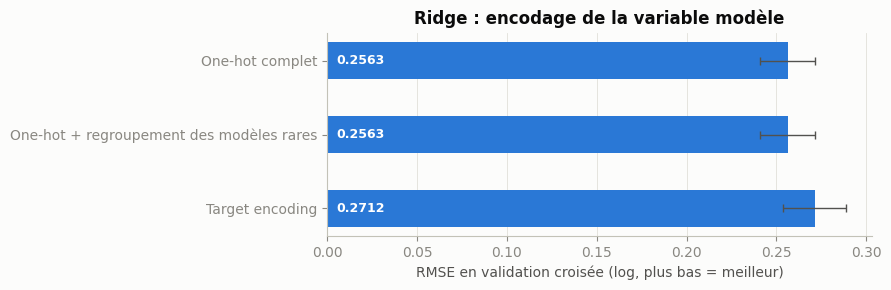

In [8]:
table = pd.DataFrame(cv_results).T.loc[encoding_names]
labels = [n.replace("Ridge, ", "") for n in encoding_names]

fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(labels, table["rmse_log (moy.)"], xerr=table["rmse_log (écart-type)"], color=C1, height=0.5,
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
for y, v in enumerate(table["rmse_log (moy.)"]):
    ax.text(0.005, y, f"{v:.4f}", va="center", color="white", fontsize=9, fontweight="bold")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE en validation croisée (log, plus bas = meilleur)")
ax.set_title("Ridge : encodage de la variable modèle")
plt.tight_layout()
plt.show()

**Constats**

- **Le regroupement des modèles rares n'apporte rien** : la validation croisée choisit le seuil le plus bas (3), et le
  score est identique au one-hot complet. La régularisation de Ridge joue déjà ce rôle : elle ramène vers 0 les
  coefficients des modèles trop rares pour être estimés, sans avoir à fixer un seuil.
- **Le target encoding est moins bon.** Il résume chaque modèle par un seul prix moyen, toutes années confondues, alors
  qu'une Golf 7 de 2014 et une de 2021 n'ont pas le même prix. Le one-hot laisse Ridge estimer l'effet du modèle
  *en même temps* que celui de l'année et du kilométrage.

On ne garde une méthode plus complexe que si son gain dépasse le bruit de la validation croisée : **l'encodage retenu
est le one-hot complet.**

In [9]:
best_encoding = table["rmse_log (moy.)"].idxmin()
gain_vs_full = table.loc["Ridge, One-hot complet", "rmse_log (moy.)"] - table["rmse_log (moy.)"].min()
noise = table["rmse_log (écart-type)"].mean()

# On ne retient une approche plus complexe que si son gain dépasse le bruit de la validation croisée
if best_encoding != "Ridge, One-hot complet" and gain_vs_full > noise / 2:
    chosen_encoding = best_encoding.replace("Ridge, ", "")
else:
    chosen_encoding = "One-hot complet"
print(f"Gain du meilleur encodage sur le one-hot complet : {gain_vs_full:.4f} (bruit de la CV ≈ {noise:.4f})")
print(f"Encodage retenu pour les modèles linéaires : {chosen_encoding}")
ridge_params = linear_search[chosen_encoding].best_params_

def make_ridge(features=FEATURES):
    model = make_linear(clone(encoding_variants[chosen_encoding][0]), features=features)
    return model.set_params(**ridge_params)

ridge_best = make_ridge()

Gain du meilleur encodage sur le one-hot complet : 0.0000 (bruit de la CV ≈ 0.0160)
Encodage retenu pour les modèles linéaires : One-hot complet


## 6. Comparaison des familles de modèles

Chaque famille est évaluée avec sa propre préparation :

- **Ridge**, avec l'encodage retenu ci-dessus ;
- **SVR** (régression à vecteurs de support, noyau RBF), avec la même préparation que Ridge et ses hyperparamètres
  optimisés sur une petite grille ;
- **Random Forest**, avec une petite grille sur la part de variables par arbre et la taille minimale des feuilles ;
- **XGBoost**, avec des hyperparamètres standards, en deux versions : avec notre imputation, ou en laissant XGBoost
  gérer lui-même les valeurs manquantes.

In [10]:
svr_search = GridSearchCV(
    make_pipeline(*imputation_steps(), linear_preprocessing(OneHotEncoder(handle_unknown="ignore")), SVR()),
    {"svr__C": [1, 3, 10], "svr__gamma": ["scale", 0.01, 0.03], "svr__epsilon": [0.05, 0.1]},
    cv=cv, scoring=SCORERS["rmse_log"], n_jobs=-1,
).fit(X_train, y_train)
print("SVR, meilleurs paramètres :", svr_search.best_params_)

rf_search = GridSearchCV(
    make_rf(n_estimators=300),
    {"randomforestregressor__max_features": [0.33, 0.5, 1.0], "randomforestregressor__min_samples_leaf": [1, 2, 4]},
    cv=cv, scoring=SCORERS["rmse_log"], n_jobs=-1,
).fit(X_train, y_train)
print("Random Forest, meilleurs paramètres :", rf_search.best_params_)

xgb_default = dict(n_estimators=300, learning_rate=0.1, max_depth=5, subsample=0.8, colsample_bytree=0.8)

evaluate_cv(f"Ridge, {chosen_encoding}", ridge_best)
evaluate_cv("SVR (RBF)", svr_search.best_estimator_)
evaluate_cv("Random Forest", rf_search.best_estimator_)
evaluate_cv("XGBoost, avec imputation", make_xgb(impute=True, **xgb_default))
evaluate_cv("XGBoost, valeurs manquantes natives", make_xgb(impute=False, **xgb_default))

family_names = ["Baseline : médiane des voitures similaires", f"Ridge, {chosen_encoding}", "SVR (RBF)",
                "Random Forest", "XGBoost, avec imputation", "XGBoost, valeurs manquantes natives"]
cv_table(family_names)

SVR, meilleurs paramètres : {'svr__C': 3, 'svr__epsilon': 0.05, 'svr__gamma': 0.03}


Random Forest, meilleurs paramètres : {'randomforestregressor__max_features': 0.5, 'randomforestregressor__min_samples_leaf': 1}


,RMSE log,MAE (TND),Erreur relative médiane
Baseline : médiane des voitures similaires,0.4216 ± 0.0044,"15,395 ± 373",17.7 %
"Ridge, One-hot complet",0.2563 ± 0.0153,"9,685 ± 642",12.3 %
SVR (RBF),0.2352 ± 0.0142,"8,380 ± 626",10.8 %
Random Forest,0.2689 ± 0.0135,"10,142 ± 475",13.1 %
"XGBoost, avec imputation",0.2584 ± 0.0070,"8,989 ± 297",10.8 %
"XGBoost, valeurs manquantes natives",0.2543 ± 0.0085,"8,942 ± 266",10.6 %


**Constats**

- **Tous les modèles battent nettement la baseline**, dont l'erreur relative médiane est de 17.7 %.
- **Un modèle linéaire bien préparé est compétitif** : avec le one-hot, Ridge atteint un RMSE de 0.256 en validation
  croisée, au niveau d'XGBoost non optimisé. L'encodage est déterminant pour cette famille : avec de simples codes
  numériques (`audi` = 2, `bmw` = 3), un modèle linéaire interpréterait BMW comme « 1,5 fois Audi ».
- **Le SVR est le meilleur modèle à ce stade** (0.235), signe que les relations ne sont pas purement linéaires.
- **XGBoost fait légèrement mieux sans notre imputation** : sa gestion native des valeurs manquantes suffit, et
  peut même tirer parti du fait qu'une information est absente. Pour XGBoost, on se passe donc d'imputation.
- **Le Random Forest est en retrait** : il ne sera pas optimisé davantage.

## 7. Optimisation et choix du modèle

**XGBoost** est optimisé par une recherche aléatoire de 40 combinaisons d'hyperparamètres (nombre d'arbres, taux
d'apprentissage, profondeur, sous-échantillonnage, régularisation…), évaluées en validation croisée.

On teste aussi une **moyenne des prédictions de Ridge et d'XGBoost optimisé**. Les deux modèles se trompent
différemment (l'un est linéaire, l'autre fonctionne par seuils) : la moyenne de deux estimateurs aux erreurs peu
corrélées est souvent plus fiable que chacun d'eux.

**Critère de choix, fixé à l'avance : la règle du un écart-type.** On repère le modèle au plus petit RMSE log en
validation croisée, puis on considère comme équivalents tous les modèles dont le score est à moins d'une **erreur
standard** de ce meilleur score (écart-type des 5 folds divisé par √5). Parmi eux, on retient **le plus simple** : un
modèle seul plutôt qu'une combinaison de deux modèles, puis le meilleur score à complexité égale. Un modèle plus simple
est plus facile à expliquer, à maintenir et à déployer, et une différence plus petite que le bruit de mesure ne justifie
pas la complexité supplémentaire.

In [11]:
xgb_space = {
    "xgbregressor__n_estimators": randint(200, 1200),
    "xgbregressor__learning_rate": loguniform(0.01, 0.2),
    "xgbregressor__max_depth": randint(3, 9),
    "xgbregressor__min_child_weight": randint(1, 10),
    "xgbregressor__subsample": uniform(0.6, 0.4),
    "xgbregressor__colsample_bytree": uniform(0.5, 0.5),
    "xgbregressor__reg_lambda": loguniform(0.1, 20),
    "xgbregressor__max_cat_to_onehot": [1, 8],
}
xgb_search = RandomizedSearchCV(make_xgb(), xgb_space, n_iter=40, cv=cv, scoring=SCORERS["rmse_log"],
                                n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
xgb_params = {k.replace("xgbregressor__", ""): v for k, v in xgb_search.best_params_.items()}
print("XGBoost, meilleurs paramètres :")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in xgb_params.items()})

xgb_tuned = make_xgb(**xgb_params)
evaluate_cv("XGBoost optimisé", xgb_tuned)

def make_ensemble(features=FEATURES):
    return VotingRegressor([("ridge", make_ridge(features)), ("xgboost", make_xgb(features, **xgb_params))])

ensemble = make_ensemble()
evaluate_cv("Moyenne Ridge + XGBoost optimisé", ensemble)

tuned_names = [f"Ridge, {chosen_encoding}", "XGBoost, valeurs manquantes natives", "XGBoost optimisé",
               "Moyenne Ridge + XGBoost optimisé"]
cv_table(tuned_names)

XGBoost, meilleurs paramètres :
{'colsample_bytree': np.float64(0.8059), 'learning_rate': np.float64(0.0152), 'max_cat_to_onehot': 8, 'max_depth': 6, 'min_child_weight': 3, 'n_estimators': 1075, 'reg_lambda': np.float64(1.525), 'subsample': np.float64(0.837)}


,RMSE log,MAE (TND),Erreur relative médiane
"Ridge, One-hot complet",0.2563 ± 0.0153,"9,685 ± 642",12.3 %
"XGBoost, valeurs manquantes natives",0.2543 ± 0.0085,"8,942 ± 266",10.6 %
XGBoost optimisé,0.2332 ± 0.0084,"8,370 ± 302",10.2 %
Moyenne Ridge + XGBoost optimisé,0.2318 ± 0.0113,"8,480 ± 430",10.6 %


Meilleur RMSE : Moyenne Ridge + XGBoost optimisé (0.2318)
Erreur standard : 0.0050  ->  seuil : 0.2369


,rmse_log (moy.),complexite
XGBoost optimisé,0.2332,1
SVR (RBF),0.2352,1
Moyenne Ridge + XGBoost optimisé,0.2318,2


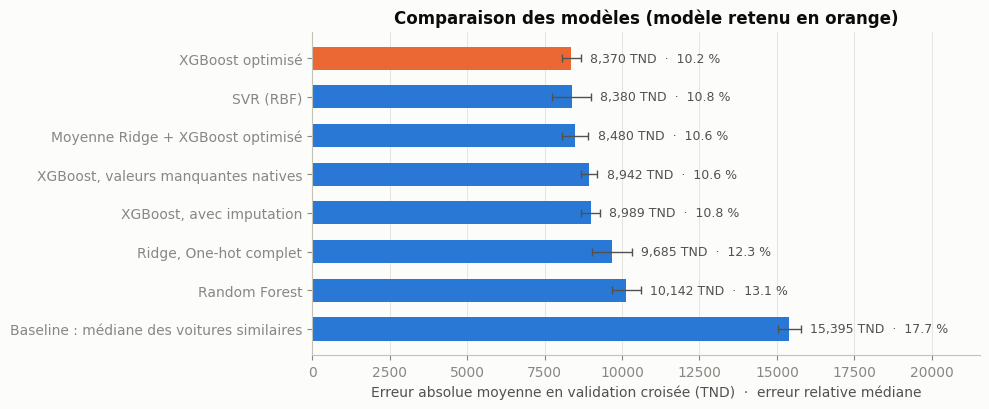

Modèle retenu : XGBoost optimisé


In [12]:
svr_params = {k.replace("svr__", ""): v for k, v in svr_search.best_params_.items()}

def make_svr(features=FEATURES):
    return make_pipeline(*imputation_steps(features), linear_preprocessing(OneHotEncoder(handle_unknown="ignore"), features),
                         SVR(**svr_params))

# Candidats au choix final, avec leur complexité (1 = un seul modèle, 2 = combinaison de deux modèles)
builders = {
    f"Ridge, {chosen_encoding}": make_ridge,
    "SVR (RBF)": make_svr,
    "XGBoost optimisé": lambda features: make_xgb(features, **xgb_params),
    "Moyenne Ridge + XGBoost optimisé": make_ensemble,
}
complexity = {name: 1 for name in builders} | {"Moyenne Ridge + XGBoost optimisé": 2}

# Règle du un écart-type : parmi les modèles à moins d'une erreur standard du meilleur RMSE,
# on retient le plus simple, puis le meilleur RMSE à complexité égale
candidates = pd.DataFrame(cv_results).T.loc[list(builders)]
best_rmse = candidates["rmse_log (moy.)"].idxmin()
standard_error = candidates.loc[best_rmse, "rmse_log (écart-type)"] / np.sqrt(cv.get_n_splits())
threshold = candidates.loc[best_rmse, "rmse_log (moy.)"] + standard_error
eligible = candidates[candidates["rmse_log (moy.)"] <= threshold].assign(complexite=lambda d: d.index.map(complexity))
best_name = eligible.sort_values(["complexite", "rmse_log (moy.)"]).index[0]

print(f"Meilleur RMSE : {best_rmse} ({candidates.loc[best_rmse, 'rmse_log (moy.)']:.4f})")
print(f"Erreur standard : {standard_error:.4f}  ->  seuil : {threshold:.4f}")
display(eligible[["rmse_log (moy.)", "complexite"]].sort_values(["complexite", "rmse_log (moy.)"]))

names = family_names + ["XGBoost optimisé", "Moyenne Ridge + XGBoost optimisé"]
table = pd.DataFrame(cv_results).T.loc[names].sort_values("mae_tnd (moy.)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [C2 if n == best_name else C1 for n in table.index]
ax.barh(table.index, table["mae_tnd (moy.)"], xerr=table["mae_tnd (écart-type)"], color=colors, height=0.6,
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
for y, (v, sd, ape) in enumerate(zip(table["mae_tnd (moy.)"], table["mae_tnd (écart-type)"], table["median_ape (moy.)"])):
    ax.text(v + sd + 300, y, f"{v:,.0f} TND  ·  {ape:.1f} %", va="center", color="#52514e", fontsize=9)
ax.set_xlim(0, table["mae_tnd (moy.)"].max() * 1.4)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Erreur absolue moyenne en validation croisée (TND)  ·  erreur relative médiane")
ax.set_title("Comparaison des modèles (modèle retenu en orange)")
plt.tight_layout()
plt.show()
print("Modèle retenu :", best_name)

**Constats**

- L'optimisation améliore nettement XGBoost : RMSE de 0.254 à 0.233, erreur relative médiane de 10.6 % à 10.2 %.
- Le meilleur RMSE est celui de la moyenne Ridge + XGBoost (0.2318), mais **XGBoost optimisé (0.2332) et le SVR
  (0.2352) sont sous le seuil d'une erreur standard (0.2369)** : les trois modèles sont statistiquement équivalents.
- La règle retient **XGBoost optimisé** : c'est un modèle seul, et le meilleur des deux modèles seuls éligibles. Il a
  d'ailleurs la plus petite erreur moyenne en dinars de tous les modèles testés (8 370 TND).

### Vérification : comparaison appariée d'XGBoost et de la moyenne Ridge + XGBoost

Les scores ci-dessus ont été obtenus sur 5 folds : l'écart entre deux modèles peut venir du découpage plutôt que des
modèles eux-mêmes. Pour trancher entre XGBoost et la moyenne Ridge + XGBoost, on les compare de façon **appariée** :
les deux modèles sont évalués **sur exactement les mêmes découpages**, répétés 5 fois avec des tirages différents
(25 folds). On mesure l'écart fold par fold, ce qui élimine la variabilité due au découpage, et on compte combien de
folds chaque modèle remporte.

In [13]:
# Mêmes découpages pour les deux modèles : validation croisée 5 folds, répétée 5 fois (25 folds)
repeated_cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
compared = ["XGBoost optimisé", "Moyenne Ridge + XGBoost optimisé"]
fold_scores = {}
for name in compared:
    res = cross_validate(builders[name](FEATURES), X_train, y_train, cv=repeated_cv, scoring=SCORERS, n_jobs=-1)
    fold_scores[name] = {m: -res[f"test_{m}"] for m in SCORERS}

rows = {}
for metric, label in [("rmse_log", "RMSE (log)"), ("mae_tnd", "MAE (TND)"), ("median_ape", "Erreur relative médiane (%)")]:
    xgb_scores, ens_scores = fold_scores[compared[0]][metric], fold_scores[compared[1]][metric]
    diff = ens_scores - xgb_scores  # > 0 : la moyenne se trompe davantage que XGBoost
    rows[label] = {
        "XGBoost optimisé": xgb_scores.mean(),
        "Moyenne Ridge + XGBoost": ens_scores.mean(),
        "Écart (moyenne − XGBoost)": diff.mean(),
        "Erreur standard de l'écart": diff.std(ddof=1) / np.sqrt(len(diff)),
        "Folds gagnés par XGBoost (%)": np.mean(diff > 0) * 100,
    }
paired = pd.DataFrame(rows).T
paired.style.format("{:.4f}").format("{:,.0f}", subset=pd.IndexSlice[["MAE (TND)"], paired.columns[:4]])     .format("{:.2f}", subset=pd.IndexSlice[["Erreur relative médiane (%)"], paired.columns[:4]])     .format("{:.0f}", subset=["Folds gagnés par XGBoost (%)"])

,XGBoost optimisé,Moyenne Ridge + XGBoost,Écart (moyenne − XGBoost),Erreur standard de l'écart,Folds gagnés par XGBoost (%)
RMSE (log),0.2323,0.2304,-0.0019,0.0008,24
MAE (TND),"8,318","8,456",138,40,68
Erreur relative médiane (%),10.13,10.61,0.47,0.08,96


**Constats**

- **La moyenne Ridge + XGBoost a un RMSE légèrement plus bas** (0.2304 contre 0.2323) : XGBoost ne fait mieux que sur 24 % des folds. Le
  RMSE pénalise fortement les grosses erreurs : en combinant deux modèles, la moyenne tempère les prédictions extrêmes.
- **XGBoost est plus précis sur une voiture typique** : erreur moyenne plus basse de 138 TND (meilleur sur 68 % des
  folds) et erreur relative médiane plus basse de 0.47 point (10.13 % contre 10.61 %), **meilleur sur 96 % des folds**.
  C'est l'écart le plus régulier des trois.
- Les deux avantages sont faibles en valeur absolue. Les folds répétés partagent une partie de leurs données, ce qui
  rend les erreurs standard un peu optimistes : seul l'écart sur l'erreur médiane est vraiment net.

**Conclusion** : pour une application de juste prix, ce qui compte pour l'utilisateur est la précision sur *sa*
voiture, mesurée par l'erreur médiane. Sur ce critère, XGBoost est meilleur ; il est aussi plus simple à déployer et à
expliquer. La comparaison appariée confirme donc le choix fait par la règle du un écart-type.

## 8. Sélection de variables

L'importance des variables est mesurée **par permutation** : on mélange aléatoirement une variable dans les données de
validation, et on mesure la dégradation du RMSE. Une variable dont le mélange ne change rien n'apporte rien au modèle.
Contrairement à l'importance intégrée à XGBoost (calculée pendant l'entraînement et biaisée vers certaines variables),
elle mesure l'effet réel sur les prédictions, et fonctionne pour n'importe quel modèle.

Elle est calculée sur les 5 folds de validation croisée, avec 5 mélanges par variable. Les variables dont la
contribution est négligeable sont ensuite retirées, et on vérifie en validation croisée que le score ne se dégrade pas.

> Une réduction de dimension de type PCA n'est pas utilisée : avec 11 variables, elle n'est pas nécessaire, elle n'a
> pas de sens sur des variables catégorielles, et elle remplacerait les variables par des combinaisons illisibles.

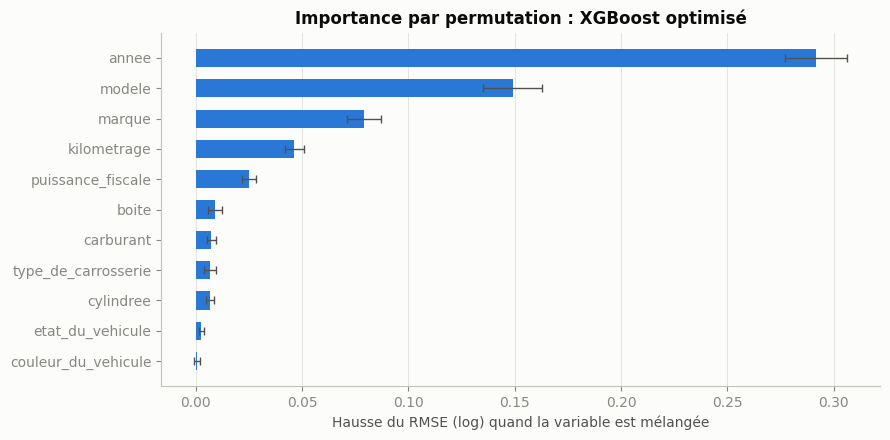

,annee,modele,marque,kilometrage,puissance_fiscale,boite,carburant,type_de_carrosserie,cylindree,etat_du_vehicule,couleur_du_vehicule
hausse du RMSE,0.2916,0.1490,0.0791,0.0463,0.0250,0.0091,0.0073,0.0066,0.0065,0.0026,0.0006
écart-type,0.0148,0.0139,0.0081,0.0045,0.0031,0.0032,0.0020,0.0027,0.0019,0.0010,0.0015


In [14]:
final_label = best_name
final_model = builders[final_label](FEATURES)

importances = []
for train_idx, val_idx in cv.split(X_train):
    fold_model = clone(final_model).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    result = permutation_importance(fold_model, X_train.iloc[val_idx], y_train.iloc[val_idx],
                                    scoring=SCORERS["rmse_log"], n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    importances.append(pd.Series(result.importances_mean, index=FEATURES))

importance = pd.concat(importances, axis=1)
perm = pd.DataFrame({"hausse du RMSE": importance.mean(axis=1), "écart-type": importance.std(axis=1)})
perm = perm.sort_values("hausse du RMSE")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(perm.index, perm["hausse du RMSE"], xerr=perm["écart-type"], color=C1, height=0.6,
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
ax.grid(axis="y", visible=False)
ax.set_xlabel("Hausse du RMSE (log) quand la variable est mélangée")
ax.set_title(f"Importance par permutation : {final_label}")
plt.tight_layout()
plt.show()
perm.sort_values("hausse du RMSE", ascending=False).T

In [15]:
# Variables candidates au retrait : contribution inférieure à 0.002 de RMSE log
weak = perm.index[perm["hausse du RMSE"] < 0.002].tolist()
print("Variables peu utiles :", weak or "aucune")

if weak:
    reduced = [f for f in FEATURES if f not in weak]
    reduced_model = builders[final_label](reduced)
    res = cross_validate(reduced_model, X_train[reduced], y_train, cv=cv, scoring=SCORERS, n_jobs=-1)
    cv_results[f"{final_label}, sans {', '.join(weak)}"] = cv_summary(res)
    display(cv_table([final_label, f"{final_label}, sans {', '.join(weak)}"]))
    full_rmse = cv_results[final_label]["rmse_log (moy.)"]
    reduced_rmse = cv_results[f"{final_label}, sans {', '.join(weak)}"]["rmse_log (moy.)"]
    SELECTED = reduced if reduced_rmse <= full_rmse else FEATURES
else:
    SELECTED = FEATURES
print("Variables retenues :", SELECTED)

Variables peu utiles : ['couleur_du_vehicule']


,RMSE log,MAE (TND),Erreur relative médiane
XGBoost optimisé,0.2332 ± 0.0084,"8,370 ± 302",10.2 %
"XGBoost optimisé, sans couleur_du_vehicule",0.2332 ± 0.0092,"8,339 ± 394",10.1 %


Variables retenues : ['kilometrage', 'annee', 'cylindree', 'puissance_fiscale', 'marque', 'modele', 'boite', 'carburant', 'type_de_carrosserie', 'etat_du_vehicule']


**Constats**

- **L'année est de loin la variable la plus importante**, suivie du modèle et de la marque. Viennent ensuite le
  kilométrage et la puissance fiscale.
- **La couleur n'apporte rien** : sa contribution est nulle aux arrondis près. Le modèle sans la couleur obtient le même
  score en validation croisée (RMSE 0.2332) : **elle est retirée.**
- L'état du véhicule et la cylindrée apportent peu mais pas rien : ils sont conservés.

## 9. Évaluation finale sur le jeu de test

Le modèle retenu est entraîné sur tout l'entraînement, puis évalué **une seule fois** sur les 852 annonces du test, mises
de côté depuis le début.

In [16]:
final_model = builders[final_label](SELECTED)
final_model.fit(X_train[SELECTED], y_train)
y_pred = final_model.predict(X_test[SELECTED])

baseline_pred = GroupMedianRegressor().fit(X_train, y_train).predict(X_test)
test_report = pd.DataFrame({"Baseline": report(y_test, baseline_pred), final_label: report(y_test, y_pred)})
test_report.style.format("{:,.3f}").format("{:,.0f}", subset=pd.IndexSlice[["MAE (TND)"], :]) \
    .format("{:.1f}", subset=pd.IndexSlice[["Erreur relative médiane (%)", "À ±10 % (%)", "À ±20 % (%)"], :])

,Baseline,XGBoost optimisé
RMSE (log),0.448,0.240
R² (log),0.487,0.853
MAE (TND),"15,308","7,870"
Erreur relative médiane (%),17.2,10.4
À ±10 % (%),32.4,48.5
À ±20 % (%),53.9,77.7


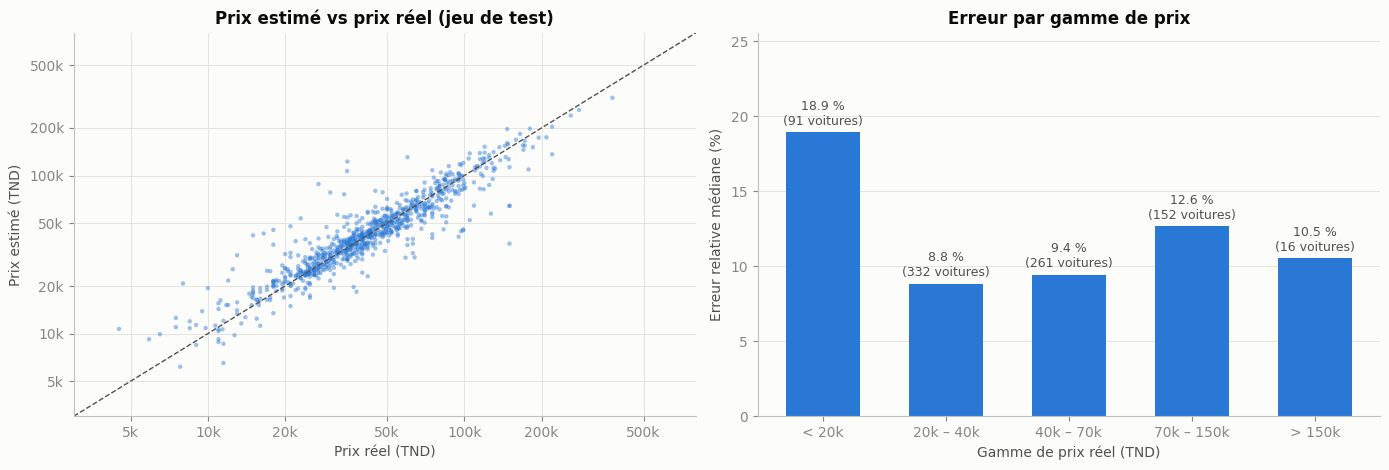

,annonces,mae_tnd,erreur_relative_mediane
prix,,,
< 20k,91,"4,264",18.9
20k – 40k,332,"4,830",8.8
40k – 70k,261,"6,705",9.4
70k – 150k,152,"16,382",12.6
> 150k,16,"29,601",10.5


In [17]:
results_test = test_df[["id_annonce", "prix", "marque", "modele", "annee", "kilometrage"]].copy()
results_test["prix_estime"] = to_tnd(y_pred)
results_test["erreur_relative"] = (results_test["prix_estime"] - results_test["prix"]) / results_test["prix"]

segments = pd.cut(results_test["prix"], [0, 20_000, 40_000, 70_000, 150_000, np.inf],
                  labels=["< 20k", "20k – 40k", "40k – 70k", "70k – 150k", "> 150k"])
by_segment = results_test.groupby(segments, observed=True).agg(
    annonces=("prix", "size"),
    mae_tnd=("erreur_relative", lambda e: np.mean(np.abs(e * results_test.loc[e.index, "prix"]))),
    erreur_relative_mediane=("erreur_relative", lambda e: np.median(np.abs(e)) * 100),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.scatter(results_test["prix"], results_test["prix_estime"], s=10, alpha=0.45, color=C1, edgecolor="none")
lims = [3_000, 800_000]
ax.plot(lims, lims, color="#52514e", lw=1, ls="--")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
ticks = [5_000, 10_000, 20_000, 50_000, 100_000, 200_000, 500_000]
ax.set_xticks(ticks, [f"{t // 1000}k" for t in ticks]); ax.set_yticks(ticks, [f"{t // 1000}k" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Prix réel (TND)"); ax.set_ylabel("Prix estimé (TND)")
ax.set_title("Prix estimé vs prix réel (jeu de test)")

ax = axes[1]
ax.bar(by_segment.index.astype(str), by_segment["erreur_relative_mediane"], color=C1, width=0.6)
for x, (v, n) in enumerate(zip(by_segment["erreur_relative_mediane"], by_segment["annonces"])):
    ax.text(x, v + 0.3, f"{v:.1f} %\n({n} voitures)", ha="center", va="bottom", color="#52514e", fontsize=9)
ax.set_ylim(0, by_segment["erreur_relative_mediane"].max() * 1.35)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Gamme de prix réel (TND)"); ax.set_ylabel("Erreur relative médiane (%)")
ax.set_title("Erreur par gamme de prix")
plt.tight_layout()
plt.show()
by_segment.style.format({"mae_tnd": "{:,.0f}", "erreur_relative_mediane": "{:.1f}"})

In [18]:
raw = pd.read_csv(RAW_DIR / "tayara_cars_all_pages.csv", usecols=["id_annonce", "titre"]).drop_duplicates("id_annonce")
worst = (results_test.merge(raw, on="id_annonce", how="left")
         .assign(ecart=lambda d: d["erreur_relative"].abs())
         .sort_values("ecart", ascending=False).head(10))
worst[["titre", "marque", "modele", "annee", "kilometrage", "prix", "prix_estime", "erreur_relative"]].style.format(
    {"prix": "{:,.0f}", "prix_estime": "{:,.0f}", "kilometrage": "{:,.0f}", "erreur_relative": "{:+.0%}"})

,titre,marque,modele,annee,kilometrage,prix,prix_estime,erreur_relative
794,prevu epave rs RAV 4 hybrid 2022,toyota,rav 4,2022,"100,000","34,996","122,659",+250%
482,transfert leasing banque zitouna toyota CHR,toyota,c-hr,2022,"66,000","27,000","88,327",+227%
37,Classe A 200 AMG Pack Night,mercedes-benz,classe a,2020,"156,000","34,900","106,646",+206%
50,À vendre voiture mercedes (douane non payée),mercedes-benz,classe b,2008,"175,000","15,000","41,810",+179%
668,Nissan Juke,nissan,juke,2024,"6,821","30,000","78,206",+161%
147,Clio 4,renault,clio,2022,"125,000","16,500","42,971",+160%
70,A vendre clio5 épave,renault,clio,2006,nan,"8,000","20,745",+159%
581,clio 5,citroen,c3 picasso,2022,nan,"18,000","45,321",+152%
398,av Nissan 9places 28478812,nissan,king cab,2010,"800,000","13,000","31,303",+141%
59,Opel kadett N' tel 50992631,opel,kadett,1982,"200,000","4,500","10,698",+138%


**Constats**

- **Sur le test, le modèle a une erreur relative médiane de 10.4 %, contre 17.2 % pour la baseline.** Près de la moitié
  des estimations sont à moins de 10 % du prix réel, plus des trois quarts à moins de 20 %.
- **Le score du test (RMSE 0.240) est cohérent avec la validation croisée (0.233)** : les choix faits en validation
  croisée n'ont pas sur-ajusté le modèle.
- **Le modèle est le plus précis pour les voitures entre 20 000 et 70 000 TND** (environ 9 % d'erreur médiane), qui
  représentent le cœur du marché. Il l'est moins pour les voitures à moins de 20 000 TND (18.9 %) : voitures anciennes,
  dont l'état réel varie beaucoup et n'est pas décrit par les variables. Au-delà de 150 000 TND, il n'y a que 16 voitures
  dans le test : le chiffre est peu fiable.
- **Les plus grosses erreurs sont toutes des surestimations, avec une cause commune** : le prix affiché ne correspond pas
  à une vente normale. On y trouve deux épaves (« prévu épave », « clio5 épave »), un « transfert de leasing » (seul le
  reste du crédit est demandé), une Mercedes « douane non payée » et un modèle mal saisi (« clio 5 » rangée sous Citroën
  C3 Picasso). Ces annonces sont identifiables par leur texte : c'est une piste concrète pour améliorer le nettoyage.

## 10. Sauvegarde du modèle

Une fois l'évaluation terminée, le modèle retenu est **réentraîné sur toutes les annonces** (entraînement et test) : plus
de données donnent un meilleur modèle, et la performance annoncée reste celle mesurée sur le test, qui n'a servi à aucun
choix.

Deux fichiers sont produits dans `models/` :

- `carfair_model.joblib` : **le pipeline complet** (imputation, encodage, modèle). L'application lui donne une annonce
  brute et reçoit un log-prix, à convertir avec `expm1`. Il n'y a plus d'encodeurs ni de scaler à gérer séparément.
- `carfair_model_metadata.json` : variables attendues, performances, date d'entraînement et versions des bibliothèques
  (un modèle sauvegardé ne se recharge de façon fiable qu'avec les mêmes versions).

In [19]:
X_all, y_all = df[SELECTED], df[TARGET]
production_model = clone(final_model).fit(X_all, y_all)

MODELS_DIR.mkdir(exist_ok=True)
dropped = [f for f in FEATURES if f not in SELECTED]
selected_key = f"{final_label}, sans {', '.join(dropped)}" if dropped else final_label  # scores CV du modèle sauvegardé
joblib.dump(production_model, MODELS_DIR / "carfair_model.joblib")

metadata = {
    "modele": final_label,
    "date_entrainement": date.today().isoformat(),
    "donnees": "data/processed/tayara_cars_cleaned.csv",
    "annonces": len(df),
    "variables": SELECTED,
    "cible": "prix_log = log1p(prix) ; prix = expm1(prediction)",
    "validation_croisee": {k: float(v) for k, v in cv_results[selected_key].items()},
    "test": {k: float(v) for k, v in report(y_test, y_pred).items()},
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                 "xgboost": xgboost.__version__, "pandas": pd.__version__},
}
(MODELS_DIR / "carfair_model_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

# Vérification : le modèle rechargé prédit un prix en dinars à partir d'une annonce brute
reloaded = joblib.load(MODELS_DIR / "carfair_model.joblib")
example = df[SELECTED].iloc[[0]]
print(f"Exemple : {example.iloc[0]['marque']} {example.iloc[0]['modele']} {example.iloc[0]['annee']}"
      f" → {to_tnd(reloaded.predict(example))[0]:,.0f} TND (prix annoncé : {df['prix'].iloc[0]:,.0f} TND)")
print("Fichiers :", [p.name for p in MODELS_DIR.glob("carfair_model*")])

Exemple : suzuki celerio 2019 → 30,593 TND (prix annoncé : 31,000 TND)
Fichiers : ['carfair_model.joblib', 'carfair_model_metadata.json']


## 11. Bilan

**Résultat** : sur des annonces jamais vues, le modèle estime le prix avec une **erreur relative médiane de 10.4 %** et
une erreur moyenne d'environ **7 900 TND**. Plus de trois estimations sur quatre sont à moins de 20 % du prix réel.

**Choix retenus**

| Question | Choix | Justification |
|---|---|---|
| Encodage de `modele` (modèles linéaires) | one-hot complet | regroupement des rares et target encoding n'apportent rien |
| Valeurs manquantes (XGBoost) | gestion native | légèrement meilleure que l'imputation |
| Modèle | XGBoost optimisé | règle du un écart-type, puis comparaison appariée : plus simple que la moyenne Ridge + XGBoost, et plus précis sur une voiture typique |
| Variables | 10 sur 11 | la couleur n'apporte rien (permutation importance) |

**Progression mesurée en validation croisée** : erreur relative médiane de 17.7 % pour la baseline, 12.3 % pour Ridge,
10.1 % pour le modèle retenu (XGBoost optimisé, sans la couleur).

**Limites**

- XGBoost, le SVR et la moyenne Ridge + XGBoost sont à égalité statistique : un autre découpage des données pourrait
  inverser leur classement.
- Le modèle ne voit ni l'état réel de la voiture, ni ses options : c'est la principale source d'erreur restante,
  surtout pour les voitures anciennes.
- Certaines annonces ont un prix qui ne reflète pas une vente normale (épave, douane non payée, transfert de leasing).

**Pistes d'amélioration**

- Repérer ces annonces atypiques par mots-clés lors du nettoyage, ou en faire des variables.
- Exploiter la ville de l'annonce (renseignée pour 43 % des annonces seulement).
- Expliquer chaque estimation dans l'application (valeurs SHAP : « l'année fait baisser le prix de X TND »).